# Southern Appalachian amphibians: 26 independent sites

A second worked example, on data where the answer is less tidy than a textbook
curve. The southern Appalachians hold more salamander genera than anywhere else on
Earth, and Stout, Jessee & McMeen (2025) built the first species–area relationships for
the region's amphibians. Their "island model" uses 26 well-surveyed sites that don't
contain one another: bogs, state and national parks, and counties in Tennessee, North
Carolina, Virginia, West Virginia and Georgia, from under a hectare to 2,114 km².

The paper fitted the power law by ordinary regression on log-transformed data. This
notebook repeats that fit, compares it with the non-linear fit `sars` makes, and then
asks the questions the package is for: is the power law the best shape, what does a
model average predict for a site nobody has surveyed, how sure is that prediction, and
is there a threshold in the relationship.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sars

## The data

The table is Appendix 2 of the paper: one row per site, with its area in km² and the
number of amphibian species recorded there, split into frogs and salamanders.

In [2]:
table = pd.read_csv("data/appalachian_island.csv")
table

,locality,area_km2,amphibians,frogs,salamanders
0,John's Bog (Blue Ridge),0.0081,10,1,9
1,Henderson Bog,0.1010,12,5,7
2,UT Arboretum,1.0100,16,9,7
3,"Sweet's Farm, Highland Co. VA",1.5700,13,5,8
4,Cantonment Area WV,3.7800,17,7,10
5,Briery Mountain WV,4.2300,14,4,10
6,Pringle Tract WV,8.5400,11,4,7
7,Harper's Ferry NHP WV,9.6500,16,6,10
8,New River SP NC,13.4500,18,7,11
9,Elk Knob SP NC,17.9000,17,4,13


`from_csv()` picks out an area column and a species column and renames them to the
`area` and `species` that every `sars` function expects. Start with all amphibians.

In [3]:
sites = sars.from_csv("data/appalachian_island.csv", area_col="area_km2", species_col="amphibians")
sites.describe().T

,count,mean,std,min,25%,50%,75%,max
area,26.0,543.299196,647.273612,0.0081,8.8175,170.605,897.4475,2114.0
species,26.0,23.423077,9.479127,10.0000,16.2500,21.500,30.0000,45.0


Area covers more than five orders of magnitude, richness less than one (10 to 45
species), so the points only spread out on log axes. Two things to notice before
fitting anything. Only two sites are smaller than 1 km², both of them bogs, so the
left end of any curve rests on very little. And among the thirteen sites larger than
250 km², richness ranges from 19 to 45: at that size, area is far from the only thing
that matters.

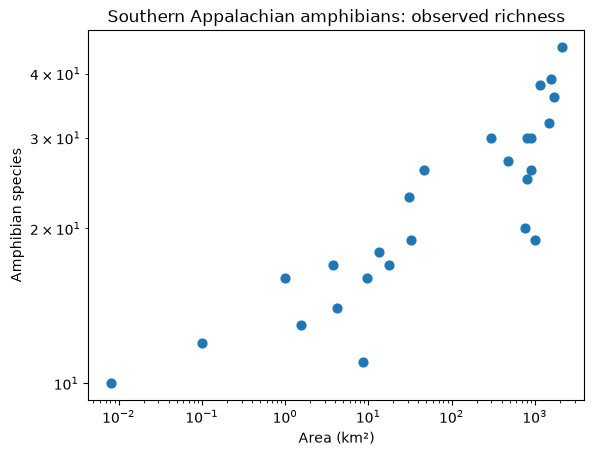

In [4]:
ax = sites.plot.scatter(x="area", y="species", s=40)
ax.set(xscale="log", yscale="log", xlabel="Area (km²)", ylabel="Amphibian species",
       title="Southern Appalachian amphibians: observed richness")
plt.show()

## Two ways to fit a power law

The power law is $S = cA^z$. Taking logs gives a straight line,
$\log S = \log c + z \log A$, and the classical fit is a linear regression of
$\log S$ on $\log A$. That is what the paper did, and `numpy.polyfit` reproduces its
published values (C = 13.92, z = 0.108, R² = 0.76).

In [5]:
log_a, log_s = np.log10(sites["area"]), np.log10(sites["species"])
z_log, intercept = np.polyfit(log_a, log_s, 1)
c_log = 10**intercept
r2_log = np.corrcoef(log_a, log_s)[0, 1] ** 2
print(f"log-log regression: c = {c_log:.2f}, z = {z_log:.4f}, R² (of log S) = {r2_log:.3f}")

log-log regression: c = 13.92, z = 0.1079, R² (of log S) = 0.757


`sar_power()` fits the same equation to the species counts themselves, by non-linear
least squares.

In [6]:
power = sars.sar_power(sites)
power

SARFit(model='power', c=12.8767  z=0.1272, R²=0.7253, AICc=163.21)

In [7]:
def r2_counts(predicted):
    """R² on the species counts, the scale sar_power() reports."""
    resid = sites["species"] - predicted
    return 1 - (resid**2).sum() / ((sites["species"] - sites["species"].mean()) ** 2).sum()


pd.DataFrame(
    {
        "c": [c_log, power.params["c"]],
        "z": [z_log, power.params["z"]],
        "R² of species counts": [r2_counts(c_log * sites["area"] ** z_log), power.r_squared],
    },
    index=["log-log regression", "sar_power (non-linear)"],
).round(4)

,c,z,R² of species counts
log-log regression,13.9206,0.1079,0.7062
sar_power (non-linear),12.8767,0.1272,0.7253


Same equation, same data, different answers: the non-linear fit has a lower `c` and a
steeper `z`. Neither is a mistake. The two methods disagree about what a "miss" is.

- The log–log regression minimises squared errors in $\log S$, so missing by 10% costs
  the same at a bog with 10 species as at a national park with 45. Every site pulls
  equally hard on the line.
- The non-linear fit minimises squared errors in species. Missing by 10% is one species
  at the bog and four or five at the park, so the species-rich sites, which here are
  the large ones, pull harder. The curve bends up to reach them and gives ground at
  the small end.

The table's last column puts both on one scale. On species counts the non-linear fit
must do at least as well, because that is the quantity it minimises; the log–log fit
would win if both were scored on $\log S$. The published R² of 0.76 is on the log
scale and isn't comparable with the 0.73 that `sar_power()` reports.

Which to use depends on what errors you expect. If scatter grows in proportion to
richness, the log–log fit matches the data better; if it is about the same number of
species everywhere, the non-linear fit does. A practical point for the rest of this
notebook: model comparison by AICc needs every model fitted to the same response, and
most of the twenty models can't be made linear by taking logs, so `sars` fits them all
to species counts.

Over most of the data the two curves are close. They part at the ends.

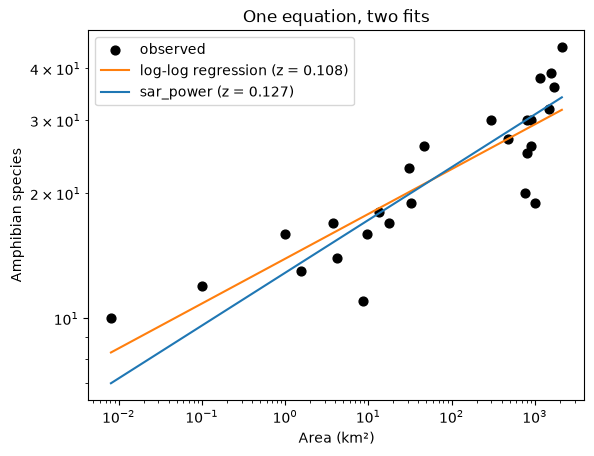

In [8]:
grid = np.geomspace(sites["area"].min(), sites["area"].max(), 200)
ax = sites.plot.scatter(x="area", y="species", s=40, color="black", label="observed")
ax.plot(grid, c_log * grid**z_log, color="C1", label=f"log-log regression (z = {z_log:.3f})")
ax.plot(grid, power.predict(grid), color="C0", label=f"sar_power (z = {power.params['z']:.3f})")
ax.set(xscale="log", yscale="log", xlabel="Area (km²)", ylabel="Amphibian species",
       title="One equation, two fits")
ax.legend()
plt.show()

Either way, `z` is low: 0.11 to 0.13, against the 0.25 to 0.35 usual for true islands.
These sites are not islands in the sea. They are samples of one continuous region and
share much of a species pool, which flattens the curve; the paper calls the design
"island" only to set it apart from its nested areas. And either way the fit is modest.
About a quarter of the variation in richness is left unexplained, and the residuals
show where: the power law overpredicts Fannin and Whitfield Counties in Georgia by
twelve and ten species and underpredicts the Great Smokies by eleven.

In [9]:
fitted = power.predict(table["area_km2"])
resid = table[["locality", "area_km2", "amphibians"]].assign(
    fitted=fitted.round(1), residual=(table["amphibians"] - fitted).round(1)
)
resid.loc[resid["residual"].abs().sort_values(ascending=False).index].head(6)

,locality,area_km2,amphibians,fitted,residual
20,Fannin Co. GA,1015.28,19,31.1,-12.1
25,Great Smokies NP,2114.00,45,34.1,10.9
15,Whitfield Co. GA,753.69,20,29.9,-9.9
21,Polk Co. TN,1144.80,38,31.5,6.5
23,Sevier Co. TN,1548.80,39,32.8,6.2
6,Pringle Tract WV,8.54,11,16.9,-5.9


## All twenty models

`sar_multi()` fits every model in the package and ranks them by AICc.

In [10]:
multi = sars.sar_multi(sites)
cols = ["model", "R2", "AICc", "delta_AICc", "weight", "shape", "asymptote"]
multi.summary[cols].round(3)

,model,R2,AICc,delta_AICc,weight,shape,asymptote
0,linear,0.736,162.179,0.000,0.212,linear,NaN
1,epm1,0.756,162.933,0.754,0.146,convex/sigmoid,NaN
2,power,0.725,163.211,1.032,0.127,convex,NaN
3,powerR,0.749,163.660,1.481,0.101,convex,NaN
4,ratio,0.736,164.993,2.814,0.052,convex,7.400239e+09
5,asymp,0.736,164.993,2.814,0.052,convex/sigmoid,7.181710e+03
6,gompertz,0.734,165.205,3.026,0.047,sigmoid,8.756200e+01
7,p2,0.731,165.521,3.342,0.040,sigmoid,NaN
8,epm2,0.730,165.567,3.388,0.039,sigmoid,NaN
9,p1,0.725,166.025,3.846,0.031,convex/sigmoid,NaN


Read this table for what it doesn't say as much as for what it does.

- **No model stands out.** The straight line $S = c + mA$ comes first with a weight of
  about 0.2, and the power law is one AICc unit behind it. Differences under two units
  are not evidence for one model over another.
- **The fits are all about equally mediocre.** Excluding the few that fail, R² runs
  from 0.66 to 0.76. Three-parameter models buy at most three points of R² over the
  power law, and AICc charges them for the extra parameter.
- **Many rows are the same curve.** `p1`, `mmf`, `heleg`, `weibull3` and `chapman`
  have exactly the power law's R²; `ratio` and `asymp` have the straight line's. Each
  has converged to its simpler special case, with the spare parameter pushed to an
  extreme. The enormous values in the `asymptote` column are the sign of that: an
  asymptote of a billion species says the data show no levelling off, not that there
  is one.
- **Two models fail.** `monod` and `negexpo` must saturate, and richness here is still
  climbing at the largest sites, so they fit badly and get no weight.

A straight line in area ranking first deserves a second look.

In [11]:
linear = next(fit for fit in multi.fits if fit.model == "linear")
print("parameters:", {k: round(float(v), 4) for k, v in linear.params.items()})

parameters: {'c': 16.5971, 'm': 0.0126}


It doesn't mean richness is proportional to area. The line starts at 16.6 species and
adds one species for every 80 km². On plain axes the 13 sites under 50 km² all sit in
a narrow strip at the left edge, with 10 to 26 species; the line passes through the
middle of that strip and on up to the large sites. It describes these 26 points as
well as anything, and would be a poor guide beyond them.

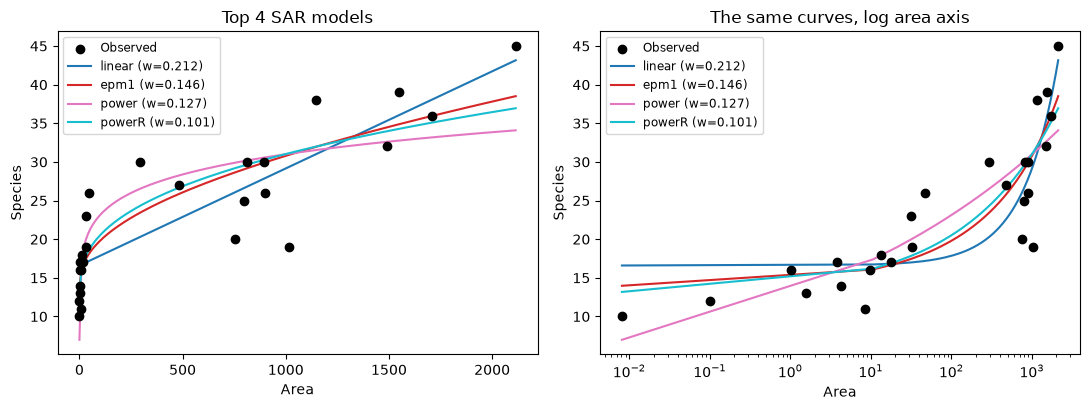

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
sars.plot_multi(multi, top_n=4, ax=axes[0])
sars.plot_multi(multi, top_n=4, ax=axes[1])
axes[1].set(xscale="log", title="The same curves, log area axis")
fig.tight_layout()
plt.show()

## Model averaging

With the weight spread this thinly, picking the top model would throw away most of the
evidence. `sar_average()` weights each model's prediction by its Akaike weight instead.

In [13]:
avg = sars.sar_average(sites)
pd.Series(avg.weights, name="weight").sort_values(ascending=False).head(6).round(3)

linear    0.212
epm1      0.146
power     0.127
powerR    0.101
ratio     0.052
asymp     0.052
Name: weight, dtype: float64

`bootstrap_ci()` puts an interval on the averaged curve: it resamples the 26 sites
with replacement, refits and re-averages, and takes percentiles of the resulting
curves. Because the areas span five orders of magnitude, pass an `area_grid` spaced
evenly in log area; the default grid is evenly spaced in area, which would put almost
every point above 20 km². Two hundred resamples take about half a minute and are
enough to see the shape of the band; use a thousand or more for a figure you publish.

In [14]:
log_grid = np.geomspace(sites["area"].min(), sites["area"].max(), 60)

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    ci = sars.bootstrap_ci(sites, n_boot=200, area_grid=log_grid, rng=np.random.default_rng(1))
print(f"{ci.n_boot} resamples, {ci.n_models_attempted} models each, {int(ci.conf * 100)}% intervals")
for w in caught:
    print("Warning:", w.message)

199 resamples, 20 models each, 95% intervals


The warnings are worth reading rather than silencing. They say that in some resamples
a model's prediction ran away somewhere on the grid, and 199 of the 200 resamples
completed. The table shows where the trouble is, with the bootstrap median beside the
limits.

In [15]:
rows = [np.argmin(abs(ci.area_grid - a)) for a in (0.01, 0.1, 0.2, 1.0, 10.0, 100.0, 1000.0)]
at = ci.area_grid[rows]
pd.DataFrame({
    "area": at,
    "lower": ci.lower[rows],
    "model average": avg.predict(at),
    "median": ci.median[rows],
    "upper": ci.upper[rows],
}).round(2)

,area,lower,model average,median,upper
0,0.01,8.50,12.33,14.49,1.085341e+79
1,0.10,10.03,13.18,13.58,1.611320e+03
2,0.19,10.79,13.53,13.65,2.021000e+01
3,1.05,12.59,14.65,14.59,1.770000e+01
4,10.71,14.25,16.86,16.95,1.892000e+01
5,109.60,15.87,20.68,20.33,2.515000e+01
6,907.56,24.78,29.54,28.98,3.229000e+01


From about 0.2 km² upwards the interval is sensible and fairly tight: a few species
either side of the curve. Below that the upper limit runs away, to 1,600 species at
0.1 km² and to astronomically large numbers at the smallest area, which is the
bootstrap reporting, truthfully, that it has little to go on there. Only two sites
are smaller than 1 km²: John's Bog at 0.008 km² and Henderson Bog at 0.1 km². About
one resample in three leaves out John's Bog and so has no data below 0.1 km², and
about one in eight leaves out both bogs and has none below 1 km². The three-parameter
models are then free to do anything at the small end, including shooting off towards
infinity. The lower limit and the median stay reasonable throughout, as the table
shows.

So the plot below cuts the band off at the top of the axes rather than letting it set
the scale, and draws the median as well. The honest reading is that these data pin the
curve down from a few tenths of a km² to 2,000 km² and say little about anything
smaller.

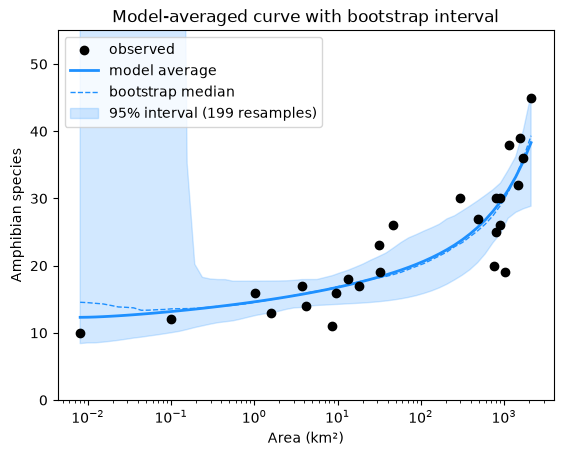

In [16]:
fig, ax = plt.subplots()
ax.scatter(sites["area"], sites["species"], color="black", zorder=3, label="observed")
ax.plot(log_grid, avg.predict(log_grid), color="dodgerblue", linewidth=2, label="model average")
ax.plot(ci.area_grid, ci.median, color="dodgerblue", linewidth=1, linestyle="--",
        label="bootstrap median")
ax.fill_between(ci.area_grid, ci.lower, np.minimum(ci.upper, 1e3), color="dodgerblue",
                alpha=0.2, label=f"{ci.conf:.0%} interval ({ci.n_boot} resamples)")
ax.set(xscale="log", ylim=(0, 55), xlabel="Area (km²)", ylabel="Amphibian species",
       title="Model-averaged curve with bootstrap interval")
ax.legend(loc="upper left")
plt.show()

## Predicting an unstudied site

The practical use the paper had in mind: how many amphibian species should a survey of
an unstudied site expect to find? Take a 50 km² tract, about the size of a large state
park and well inside the range of the data.

In [17]:
new_area = 50.0
pd.DataFrame(
    {"predicted species": [c_log * new_area**z_log, float(power.predict(new_area)),
                           float(avg.predict(new_area))]},
    index=["log-log regression", "sar_power", "model average"],
).round(1)

,predicted species
log-log regression,21.2
sar_power,21.2
model average,19.1


In [18]:
# The bootstrap grid has no point at exactly 50 km², so read the band off between its neighbours.
lower = np.interp(np.log(new_area), np.log(ci.area_grid), ci.lower)
upper = np.interp(np.log(new_area), np.log(ci.area_grid), ci.upper)
spread = float(np.std(sites["species"] - avg.predict(sites["area"])))
print(f"95% interval for the averaged curve at {new_area:g} km²: {lower:.1f} to {upper:.1f} species")
print(f"typical distance of a site from the curve: {spread:.1f} species")

95% interval for the averaged curve at 50 km²: 14.9 to 22.9 species
typical distance of a site from the curve: 4.4 species


All three methods say about 19 to 21 species, and the bootstrap interval is about
eight species wide. Be clear about what that interval covers. It is the uncertainty in the
*average* richness of sites of this size: where the curve is. A single site is another
matter. The 26 sites sit about four species from the curve on average, and some
miss by ten, so a fair statement for one unsurveyed 50 km² tract is "around 20, and
anything from the low teens to the high twenties would be unremarkable". Elevation,
habitat and survey effort, none of which is in the model, decide where in that range a
real site falls.

## Is there a threshold?

`sar_threshold()` fits piecewise-linear models of species against the natural log of
area and compares them with a single straight line. `ZslopeOne` is flat below its
breakpoint, the classic small-island effect; `ContOne` has two different slopes.

In [19]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    th = sars.sar_threshold(sites)
for w in caught:
    print("Warning:", w.message)
print(th)
th.summary.round(3)

ThresholdFit(best='ContOne', breakpoint=6.920 (ln area), breakpoint_area=1012)


,model,breakpoint,breakpoint_area,breakpoint2,breakpoint2_area,AIC,AICc,BIC,R2
0,ContOne,6.92,1012.270,NaN,NaN,154.331,157.331,160.622,0.825
1,ZslopeOne,1.77,5.871,NaN,NaN,164.620,166.524,169.652,0.720
2,Linear,NaN,NaN,NaN,NaN,167.851,168.942,171.625,0.658


In [20]:
pd.DataFrame(th.best_segments).assign(
    area_from=lambda d: np.exp(d["x_min"]), area_to=lambda d: np.exp(d["x_max"])
)[["area_from", "area_to", "intercept", "slope"]].round(2)

,area_from,area_to,intercept,slope
0,0.01,1012.27,14.57,1.72
1,1012.27,2114.00,-137.56,23.70


There is a threshold, but not the one the function is usually asked about.

**No small-island effect.** The flat-then-rising model is only two AICc units better
than the straight line and nine worse than the two-slope model. With two sites under
1 km² there was never much chance of detecting one.

**A steepening at about 1,000 km².** The two-slope model wins clearly. Below the
breakpoint richness rises by 1.7 species for each unit of ln(area), which is about
four species per tenfold increase in area. Above it the slope is fourteen times
steeper. Its AICc (157.3) is also about five units better than the best of the twenty
smooth models above, a comparison that is fair because both are fitted to species
counts.

Before reading biology into that, three cautions.

1. The upper segment rests on six sites between 1,015 and 2,114 km², only a doubling
   of area. A slope estimated over so short a range is fragile.
2. Those six sites are Fannin County (19 species) at the bottom and Polk, Hamilton,
   Sevier and Buncombe Counties and the Great Smoky Mountains (32 to 45 species) above
   it. Four of the five rich ones take in the high Blue Ridge and Great Smokies, the
   centre of salamander diversity. What changes at the breakpoint may be which
   mountains a site includes rather than how big it is.
3. These models are straight lines in ln(area). A power law is not: on these axes it
   curves upward, and a two-slope line is the nearest a piecewise-linear model can get
   to a curve. Some of ContOne's advantage over the straight line is just that.

The plot shows all of this at once.

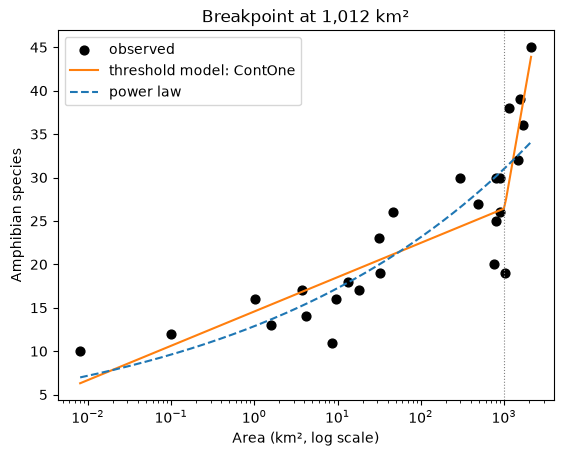

In [21]:
ax = sites.plot.scatter(x="area", y="species", s=40, color="black", label="observed")
ax.plot(grid, th.predict(grid), color="C1", label=f"threshold model: {th.best_model}")
ax.plot(grid, power.predict(grid), color="C0", linestyle="--", label="power law")
ax.axvline(th.breakpoint_area, color="grey", linewidth=0.8, linestyle=":")
ax.set(xscale="log", xlabel="Area (km², log scale)", ylabel="Amphibian species",
       title=f"Breakpoint at {th.breakpoint_area:,.0f} km²")
ax.legend()
plt.show()

## Frogs and salamanders separately

The amphibian total hides two groups that need not behave alike. Fitting the power law
to each takes one `from_csv()` call per group.

In [22]:
rows = {}
for group in ("amphibians", "frogs", "salamanders"):
    d = sars.from_csv("data/appalachian_island.csv", area_col="area_km2", species_col=group)
    fit = sars.sar_power(d)
    rows[group] = {"c": fit.params["c"], "z": fit.params["z"], "R²": fit.r_squared}
pd.DataFrame(rows).T.round(3)

,c,z,R²
amphibians,12.877,0.127,0.725
frogs,4.977,0.109,0.655
salamanders,7.854,0.138,0.581


Salamanders, the group the region is famous for, are the ones area explains worst
(R² = 0.58). That fits the reading of the threshold above: salamander richness in the
southern Appalachians follows elevation and moist forest more than it follows the
size of the area surveyed. Whitfield County, Georgia, has 754 km² and 8 salamander
species; John's Bog has less than a hectare and 9.

## What to take from this

- The power law is a reasonable summary of these data and not a privileged one. Four
  models are within two AICc units of each other, and the best of the twenty explain
  about three-quarters of the variation (R² of 0.73 to 0.76). The two-slope threshold
  model reaches 0.83.
- How the power law is fitted changes its parameters, here from z = 0.108 to
  z = 0.127. Say which method you used, and compare R² only between fits to the same
  response.
- Predictions between about 1 and 2,000 km² are stable across methods. Below about
  0.2 km² the bootstrap shows there is almost no information.
- Area leaves a lot unexplained. The largest residuals and the breakpoint both point
  at the same thing: which sites include the high mountains.

### References

- Arrhenius O (1921). Species and area. *Journal of Ecology*, 9, 95–99.
- Matthews TJ, Rigal F (2021). Thresholds and the species–area relationship. *Frontiers
  of Biogeography*, 13, e49404.
- Stout JB, Jessee LD, McMeen JN (2025). Nested and island models for determining the
  species-area relationship of southern Appalachian amphibians. *Journal of North
  American Herpetology*, 2025(1), 1–7.
  [doi:10.17161/jnah.v2025i1.21974](https://doi.org/10.17161/jnah.v2025i1.21974)